In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import energyflow as ef
from energyflow.utils import gen_massless_phase_space
from energyflow import EFPSet
import os
import glob
import time
from RegressFunctions import *
from RestrictedEFPs import efps_chunked
from PhysicsFunctions import *
from scipy.special import gammaln, digamma, polygamma, zeta
from scipy.interpolate import UnivariateSpline
from scipy.optimize import brentq

os.makedirs('figures', exist_ok=True)

In [2]:
labels = {'Z': r'$Z\to u\bar u$', 
          'Z1': r'$Z\to u\bar u$, 1 splitting, $\sqrt{s} = m_Z$, running $\alpha_s$', 
          'Z1_500GeV': r'$Z\to u\bar u$, 1 splitting, $\sqrt{s} = 500$ GeV', 
          'Z1_1TeV': r'$Z\to u\bar u$, 1 splitting, $\sqrt{s} = 1$ TeV',
          'Z1_fix08': r'$Z\to u\bar u$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.08$',
          'Z1_fix12': r'$Z\to u\bar u$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.12$',
          'Z1_fix16': r'$Z\to u\bar u$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.16$',
          'Z1_fix05': r'$Z\to u\bar u$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.05$',
          'Z1_fix50': r'$Z\to u\bar u$ 1 splitting, $\sqrt{s} = m_Z$, fixed $\alpha_s = 0.50$',
          }

## Import Spectra 

In [3]:
keys = ['Z1', 'Z1_500GeV', 'Z1_1TeV', 'Z1_fix08', 'Z1_fix12', 'Z1_fix16', 'Z1_fix05', 'Z1_fix50']
depth, nq, M = 4, 2048, 20000
nw, nz = 500, 500

### NTK spectra: λ_k for k = 1..M (dense eigvalsh)
NTK_5 = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/NTK_d{depth}_Q_nq{nq}_M{5000}_{k}.npy')}
NTK_20 = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/NTK_d{depth}_Q_nq{nq}_M{20000}_{k}.npy')}
NTK_30 = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/NTK_d{depth}_Q_nq{nq}_M{30000}_{k}.npy')}


### Reconstructed spectra: rows (k, λ) from the dimension curves
# Analytic
# REC_AN = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/Reconstructed_Analytic_{k}.npy')}
REC_AN = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/Reconstructed_Analytic_nw{nw}_nz{nz}_{k}.npy')}
# Pythia
REC_PY = {k: np.load(f) for k in keys if os.path.exists(f := f'spectra/Reconstructed_Pythia_M{M}_{k}.npy')}

print(NTK_5.keys())

dict_keys(['Z1', 'Z1_500GeV', 'Z1_1TeV', 'Z1_fix08', 'Z1_fix12', 'Z1_fix16', 'Z1_fix05', 'Z1_fix50'])


## Import $r$ measurement

In [4]:
M_tp, nseeds = 10_000, 20
TARGET = {key: np.load(f) for key in keys if os.path.exists(f := f'spectra/TARGETPOWER_NTK_d{depth}_Q_nq2048_M{M_tp}_nseeds{nseeds}_{key}.npy')}

## Import Losses

In [5]:
λ, depth = 1e-10, 4
KRR = {key: np.load(f) for key in keys if os.path.exists(f := f'losses/KRR_NTK_d{depth}_lam{λ:g}_{key}.npz')}

## Plot Spectra Together 
## (Direct NTK, Reconstructed from Pythia, and Reconstructed from Analytic) 

(1.0, 5000.0)

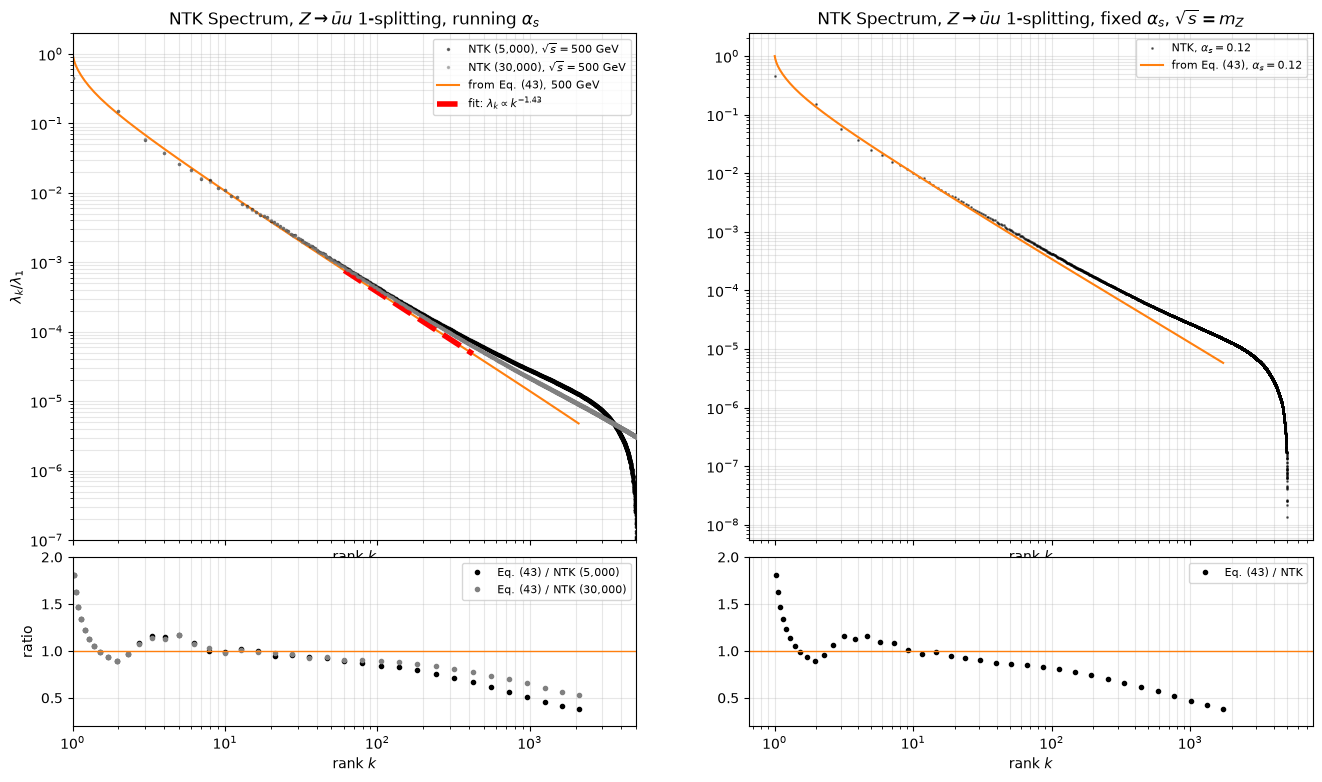

In [6]:
fig, ((ax1, ax2), (r1, r2)) = plt.subplots(2, 2, figsize=(16, 9), sharex='col', gridspec_kw=dict(height_ratios=[3, 1], hspace=0.05))
kk = lambda lam: np.arange(1, len(lam) + 1)
norm = lambda key, k: NTK_5[key][int(k[0]) - 1] / NTK_5[key][0]      # pin a reconstructed curve to the NTK value at its first k
ntk_at = lambda D, key, k: np.exp(np.interp(np.log(k), np.log(kk(D[key])), np.log(D[key]/D[key][0])))   # NTK/λ1 interpolated at the reconstruction's k
scale = 0.45   # (by hand) 

# left: energy scan, running alpha_s
# ax1.loglog(kk(NTK['Z1']), scale*NTK['Z1']/NTK['Z1'][0], '.', color='C0', markersize=2, alpha=0.5, label=r'NTK, $\sqrt{s} = m_Z$')
ax1.loglog(kk(NTK_5['Z1_500GeV']), scale*NTK_5['Z1_500GeV']/NTK_5['Z1_500GeV'][0], '.', color='k', markersize=3, alpha=0.5, label=r'NTK (5,000), $\sqrt{s} = 500$ GeV', zorder=10)
ax1.loglog(kk(NTK_30['Z1_500GeV']), scale*NTK_30['Z1_500GeV']/NTK_30['Z1_500GeV'][0], '.', color='gray', markersize=3, alpha=0.5, label=r'NTK (30,000), $\sqrt{s} = 500$ GeV', zorder=10)
# ax1.loglog(kk(NTK['Z1_1TeV']), scale*NTK['Z1_1TeV']/NTK['Z1_1TeV'][0], '.', color='C2', markersize=2, alpha=0.5, label=r'NTK, $\sqrt{s} = 1$ TeV')
# k, lam = REC_PY['Z1'];        ax1.loglog(k, lam*norm('Z1', k), 'o', color='C0', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $m_Z$')
# k, lam = REC_PY['Z1_500GeV']; ax1.loglog(k, lam*norm('Z1_500GeV', k), 'o', color='C1', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, 500 GeV')
# k, lam = REC_PY['Z1_1TeV'];   ax1.loglog(k, lam*norm('Z1_1TeV', k), 'o', color='C2', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, 1 TeV')
# k, lam = REC_AN['Z1'];        ax1.loglog(k, lam*norm('Z1', k), '-', color='C0', label=r'from Eq. (43), $m_Z$')
k, lam = REC_AN['Z1_500GeV']; ax1.loglog(k, lam*norm('Z1_500GeV', k), '-', color='C1', label=r'from Eq. (43), 500 GeV')
# k, lam = REC_AN['Z1_1TeV'];   ax1.loglog(k, lam*norm('Z1_1TeV', k), '-', color='C2', label=r'from Eq. (43), 1 TeV')
###### Ratio Plot ######
r1.semilogx(k, lam*norm('Z1_500GeV', k)/(scale*ntk_at(NTK_5, 'Z1_500GeV', k)), '.', color='k', label='Eq. (43) / NTK (5,000)')
r1.semilogx(k, lam*norm('Z1_500GeV', k)/(scale*ntk_at(NTK_30, 'Z1_500GeV', k)), '.', color='gray', label='Eq. (43) / NTK (30,000)')
###### Fit ######
lo, hi = 5e1, 5e2
m = (k >= lo) & (k <= hi)
fit = np.polyfit(np.log(k[m]), np.log(lam[m]), 1);  alpha = -fit[0]
ax1.loglog(k[m], np.exp(np.polyval(fit, np.log(k[m])))*norm('Z1_500GeV', k), '--', color='r', lw=4, label=rf'fit: $\lambda_k \propto k^{{-{alpha:.2f}}}$')
ax1.set_title(r'NTK Spectrum, $Z\rightarrow \bar{u}u$ 1-splitting, running $\alpha_s$'); 
ax1.set_xlabel('rank $k$'); 
ax1.set_ylabel(r'$\lambda_k/\lambda_1$')
ax1.legend(fontsize=8); ax1.grid(True, which='both', alpha=0.3)

# right: fixed alpha_s at mZ
# ax2.loglog(kk(NTK['Z1_fix08']), scale*NTK['Z1_fix08']/NTK['Z1_fix08'][0], '.', color='C0', markersize=2, alpha=0.5, label=r'NTK, $\alpha_s = 0.08$')
ax2.loglog(kk(NTK_5['Z1_fix12']), scale*NTK_5['Z1_fix12']/NTK_5['Z1_fix12'][0], '.', color='k', markersize=2, alpha=0.5, label=r'NTK, $\alpha_s = 0.12$')
# ax2.loglog(kk(NTK['Z1_fix16']), scale*NTK['Z1_fix16']/NTK['Z1_fix16'][0], '.', color='C2', markersize=2, alpha=0.5, label=r'NTK, $\alpha_s = 0.16$')
# k, lam = REC_PY['Z1_fix08'];  ax2.loglog(k, lam*norm('Z1_fix08', k), 'o', color='C0', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $\alpha_s = 0.08$')
# k, lam = REC_PY['Z1_fix12'];  ax2.loglog(k, lam*norm('Z1_fix12', k), 'o', color='C1', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $\alpha_s = 0.12$')
# k, lam = REC_PY['Z1_fix16'];  ax2.loglog(k, lam*norm('Z1_fix16', k), 'o', color='C2', markersize=4, mfc='none', label=r'from Pythia $d(Q)$, $\alpha_s = 0.16$')
# k, lam = REC_AN['Z1_fix08'];  ax2.loglog(k, lam*norm('Z1_fix08', k), '-', color='C0', label=r'from Eq. (43), $\alpha_s = 0.08$')
k, lam = REC_AN['Z1_fix12'];  ax2.loglog(k, lam*norm('Z1_fix12', k), '-', color='C1', label=r'from Eq. (43), $\alpha_s = 0.12$')
# k, lam = REC_AN['Z1_fix16'];  ax2.loglog(k, lam*norm('Z1_fix16', k), '-', color='C2', label=r'from Eq. (43), $\alpha_s = 0.16$')
ax2.set_title(r'NTK Spectrum, $Z\rightarrow \bar{u}u$ 1-splitting, fixed $\alpha_s$, $\sqrt{s} = m_Z$'); 
ax2.set_xlabel('rank $k$')
ax2.legend(fontsize=8); ax2.grid(True, which='both', alpha=0.3)
r2.semilogx(k, lam*norm('Z1_fix12', k)/(scale*ntk_at(NTK_5, 'Z1_fix12', k)), '.', color='k', label='Eq. (43) / NTK')


for r in (r1, r2):
    r.axhline(1, color='C1', lw=1); 
    # r.set_yscale('log'); 
    r.set_ylim(0.2, 2); 
    r.set_xlabel('rank $k$'); 
    r.grid(True, which='both', alpha=0.3); 
    r.legend(fontsize=8)
r1.set_ylabel('ratio')
ax1.set_ylim(1e-7, 2); ax1.set_xlim(1e0, 5e3)

## Plot Learning Curve

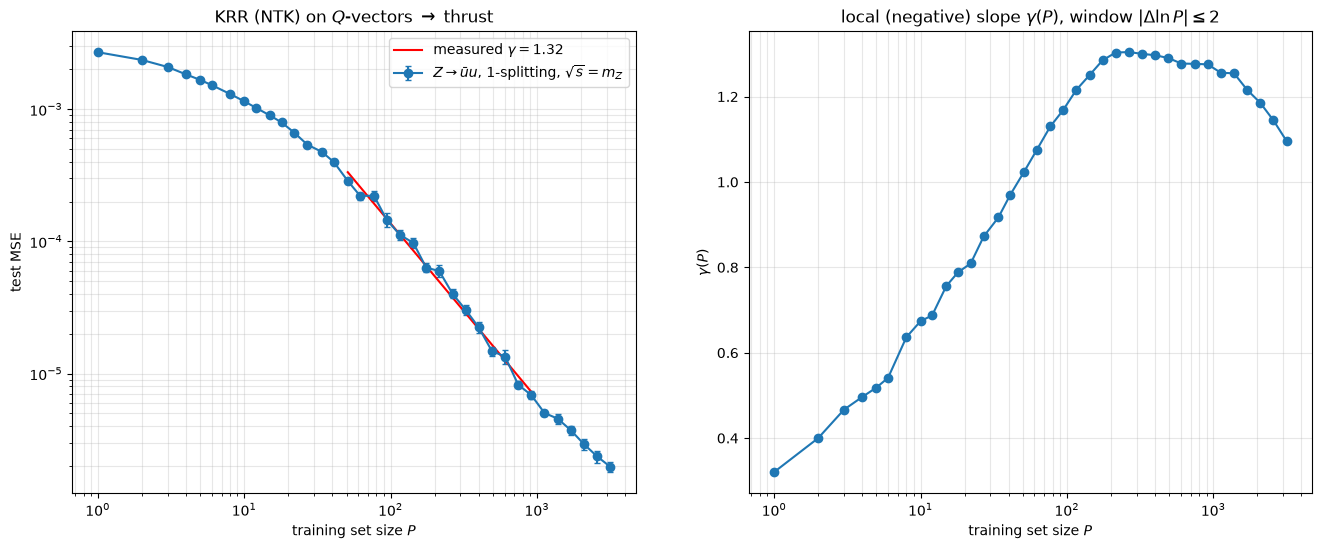

In [7]:
key = 'Z1'
λ, w = 1e-10, 2
Ps, L, S, reps = KRR[key]['Ps'], KRR[key]['loss'], KRR[key]['std'], KRR[key]['reps']
P, local_gamma = local_slope(L, k=Ps, kmax=np.inf, w=w)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
ax1.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C0', capsize=2, label=r'$Z\rightarrow \bar{u}u$, 1-splitting, $\sqrt{s} = m_Z$')
# fit 
lo, hi = 5e1, 1e3
mask = (Ps > lo) & (Ps < hi)
fit = np.polyfit(np.log(Ps[mask]), np.log(L[mask]), 1)
gamma = -fit[0]
ax1.loglog(Ps[mask], np.exp(np.polyval(fit, np.log(Ps[mask]))), 'r-', label=rf'measured $\gamma = {gamma:.2f}$')
# 
ax1.set_title(rf'KRR (NTK) on $Q$-vectors $\to$ thrust'); 
ax1.set_xlabel('training set size $P$'); 
ax1.set_ylabel('test MSE')
ax1.set_xscale('log'); ax1.set_yscale('log'); 
ax1.grid(True, which='both', alpha=0.3); ax1.legend()

ax2.plot(P, local_gamma, 'o-', color='C0')
ax2.set_title(rf'local (negative) slope $\gamma(P)$, window $|\Delta \ln P| \leq {w}$'); 
ax2.set_xlabel('training set size $P$'); 
ax2.set_ylabel(r'$\gamma(P)$')
ax2.set_xscale('log'); ax2.grid(True, which='both', alpha=0.3)

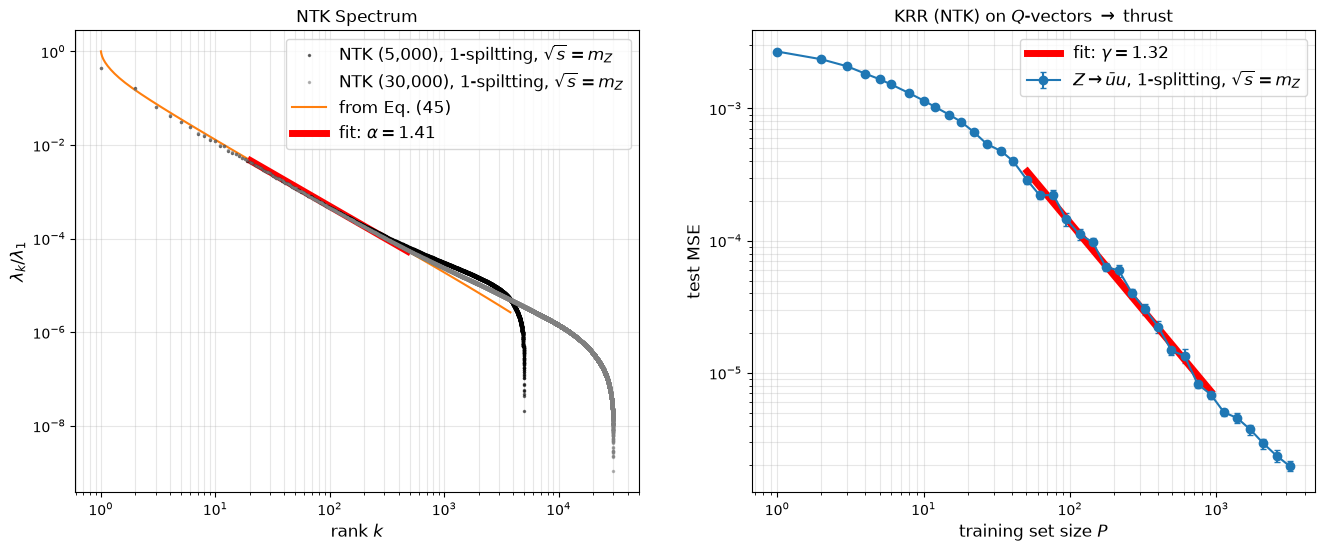

In [8]:
key = 'Z1'
λ, w = 1e-10, 2
Ps, L, S, reps = KRR[key]['Ps'], KRR[key]['loss'], KRR[key]['std'], KRR[key]['reps']
P, local_gamma = local_slope(L, k=Ps, kmax=np.inf, w=w)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))


## LEFT: NTK \alpha
k, lam = REC_AN[key]; 
ax1.loglog(kk(NTK_5[key]), scale*NTK_5[key]/NTK_5[key][0], '.', color='k', markersize=3, alpha=0.5, label=r'NTK (5,000), 1-spiltting, $\sqrt{s} = m_Z$', zorder=10)
ax1.loglog(kk(NTK_30[key]), scale*NTK_30[key]/NTK_20[key][0], '.', color='gray', markersize=3, alpha=0.5, label=r'NTK (30,000), 1-spiltting, $\sqrt{s} = m_Z$', zorder=10)

ax1.loglog(k, lam*norm(key, k), '-', color='C1', label=r'from Eq. (45)')
###### Fit ######
lo, hi = 2e1, 5e2
m = (k >= lo) & (k <= hi)
fit = np.polyfit(np.log(k[m]), np.log(lam[m]), 1);  alpha = -fit[0]
ax1.loglog(k[m], np.exp(np.polyval(fit, np.log(k[m])))*norm(key, k), color='r', lw=5, label=rf'fit: $\alpha = {alpha:.2f}$')
#################
# ax1.set_title(r'NTK Spectrum, $Z\rightarrow \bar{u}u$ 1-splitting, running $\alpha_s$'); 
ax1.set_title(r'NTK Spectrum')
ax1.set_xlabel('rank $k$', fontsize=12); 
ax1.set_ylabel(r'$\lambda_k/\lambda_1$', fontsize=12)
ax1.legend(fontsize=12); ax1.grid(True, which='both', alpha=0.3)


## RIGHT: Learning Curve
ax2.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C0', capsize=2, label=r'$Z\rightarrow \bar{u}u$, 1-splitting, $\sqrt{s} = m_Z$')
###### Fit ######
lo, hi = 5e1, 1e3
mask = (Ps > lo) & (Ps < hi)
fit = np.polyfit(np.log(Ps[mask]), np.log(L[mask]), 1)
gamma = -fit[0]
ax2.loglog(Ps[mask], np.exp(np.polyval(fit, np.log(Ps[mask]))), 'r-', lw=5, label=rf'fit: $\gamma = {gamma:.2f}$')
#################
ax2.set_title(rf'KRR (NTK) on $Q$-vectors $\to$ thrust'); 
ax2.set_xlabel('training set size $P$', fontsize=12); 
ax2.set_ylabel('test MSE', fontsize=12)
ax2.set_xscale('log'); ax1.set_yscale('log'); 
ax2.grid(True, which='both', alpha=0.3); ax2.legend(fontsize=12)

## Plot NTK Spec, $r$ Measurement, Learning Curve together 

In [23]:
def plot_scaling(key, window_alpha=(100, 1000), window_r=(20, 300), window_gamma=(200, 2000)):
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))
    scale = 0.45 
    ## LEFT: NTK alpha ####################################################################
    lo, hi = window_alpha
    k, lam_analytic = REC_AN[key]
    ax1.loglog(kk(NTK_5[key]), scale*NTK_5[key]/NTK_5[key][0], '.', color='k', markersize=3, alpha=0.5, label=r'NTK (5,000)', zorder=10)
    ax1.loglog(kk(NTK_30[key]), scale*NTK_30[key]/NTK_30[key][0], '.', color='gray', markersize=3, alpha=0.5, label=r'NTK (30,000)', zorder=10)
    ax1.loglog(k, lam_analytic*norm(key, k), '-', color='C1', label=r'from Eq. (45)')
    m = (k >= lo) & (k <= hi)
    fit = np.polyfit(np.log(k[m]), np.log(lam_analytic[m]), 1);  alpha = -fit[0]
    ax1.loglog(k[m], np.exp(np.polyval(fit, np.log(k[m])))*norm(key, k), 'r--', lw=5, label=rf'fit: $\alpha = {alpha:.2f}$')
    ax1.set_title(r'NTK Spectrum'); ax1.set_xlabel('rank $k$', fontsize=12); ax1.set_ylabel(r'$\lambda_k/\lambda_1$', fontsize=12)
    ax1.legend(fontsize=12); ax1.grid(True, which='both', alpha=0.3)

    ## MIDDLE: measured r ####################################################################
    lo, hi = window_r
    lam, v2 = TARGET[key]
    k = np.arange(1, len(lam) + 1)
    tail = np.cumsum(v2[::-1])[::-1]       # reverse, cumsum, reverse back -> sum over j >= k
    mask = (k >= lo) & (k <= hi)
    fit = np.polyfit(np.log(lam[mask]), np.log(np.sqrt(tail[mask])), 1);  r = fit[0]
    ax2.loglog(lam, np.sqrt(tail), '.', ms=3, color='b', label=rf'Thrust $\bar w_j$, NTK (10,000) $\lambda_j$')
    ax2.loglog(lam[mask], np.exp(np.polyval(fit, np.log(lam[mask]))), 'r--', lw=5, label=rf'fit: $r = {r:.2f}$')
    ax2.set_title(r'Measurement of $r$'); ax2.set_xlabel(r'$\lambda_k$', fontsize=12)
    ax2.set_ylabel(r'$\left[\sum_{j\geq k} \bar w_j^2\lambda_j\right]^{1/2} \;\sim\; \lambda_k^{\,r}$', fontsize=12)
    ax2.legend(fontsize=12)

    ## RIGHT: Learning Curve ##################################################################
    lo, hi = window_gamma
    Ps, L, S, reps = KRR[key]['Ps'], KRR[key]['loss'], KRR[key]['std'], KRR[key]['reps']
    ax3.errorbar(Ps, L, S/np.sqrt(reps), fmt='o-', color='C0', capsize=2, label=r'KRR, $\lambda = 10^{-10}$')
    mask = (Ps > lo) & (Ps < hi)
    fit = np.polyfit(np.log(Ps[mask]), np.log(L[mask]), 1);  gamma = -fit[0]
    ax3.loglog(Ps[mask], np.exp(np.polyval(fit, np.log(Ps[mask]))), 'r--', lw=5, label=rf'fit: $\gamma = {gamma:.2f}$')
    ax3.set_title(r'KRR (NTK) on $Q$-vectors $\to$ Thrust'); ax3.set_xlabel('training set size $P$', fontsize=12); ax3.set_ylabel('test loss', fontsize=12)
    ax3.set_xscale('log'); ax3.set_yscale('log'); ax3.grid(True, which='both', alpha=0.3); ax3.legend(fontsize=12)

    fig.suptitle(rf'{labels[key]}', fontsize=16)
    print(f'{key}:  alpha = {alpha:.2f},  r = {r:.2f},  2*alpha*r = {2*alpha*r:.2f},  gamma = {gamma:.2f}')
    return alpha, r, gamma

Z1:  alpha = 1.41,  r = 0.48,  2*alpha*r = 1.36,  gamma = 1.36
Z1_1TeV:  alpha = 1.45,  r = 0.45,  2*alpha*r = 1.30,  gamma = 1.54


(np.float64(1.451928094047689),
 np.float64(0.44937291034984195),
 np.float64(1.5429513418859622))

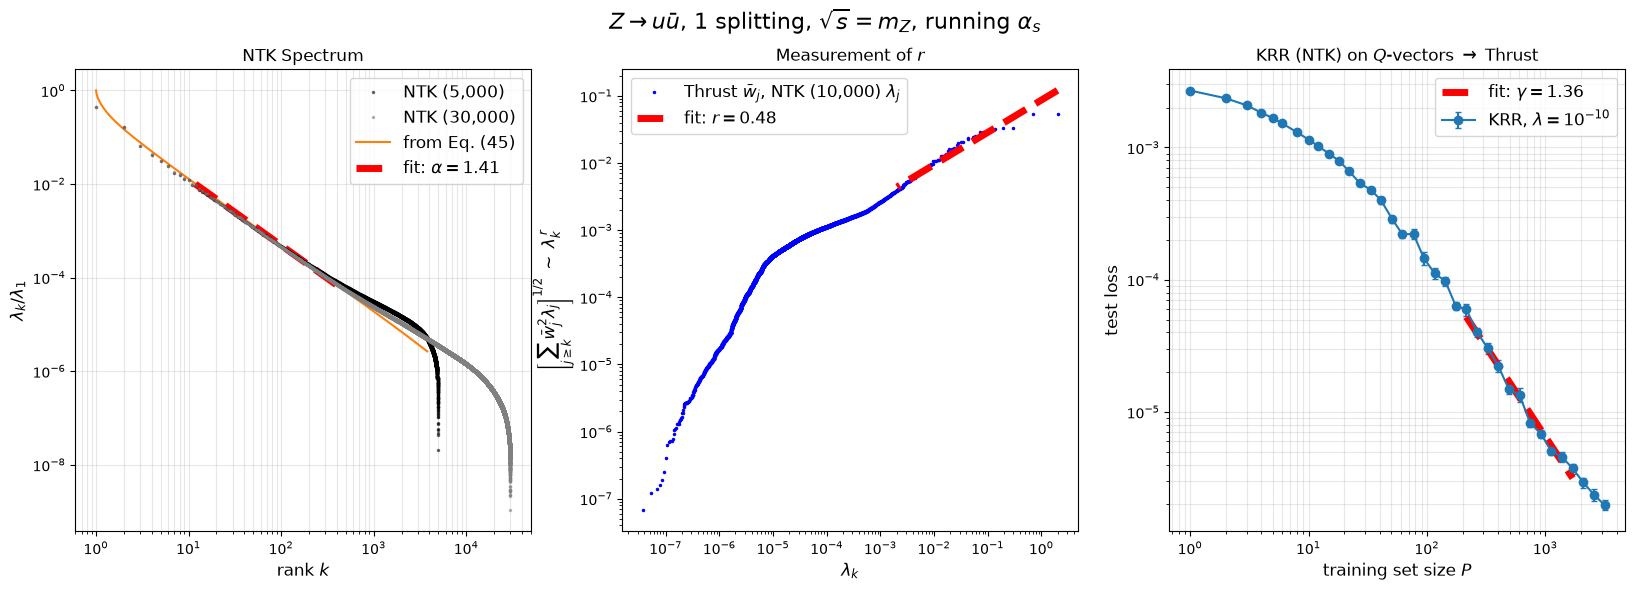

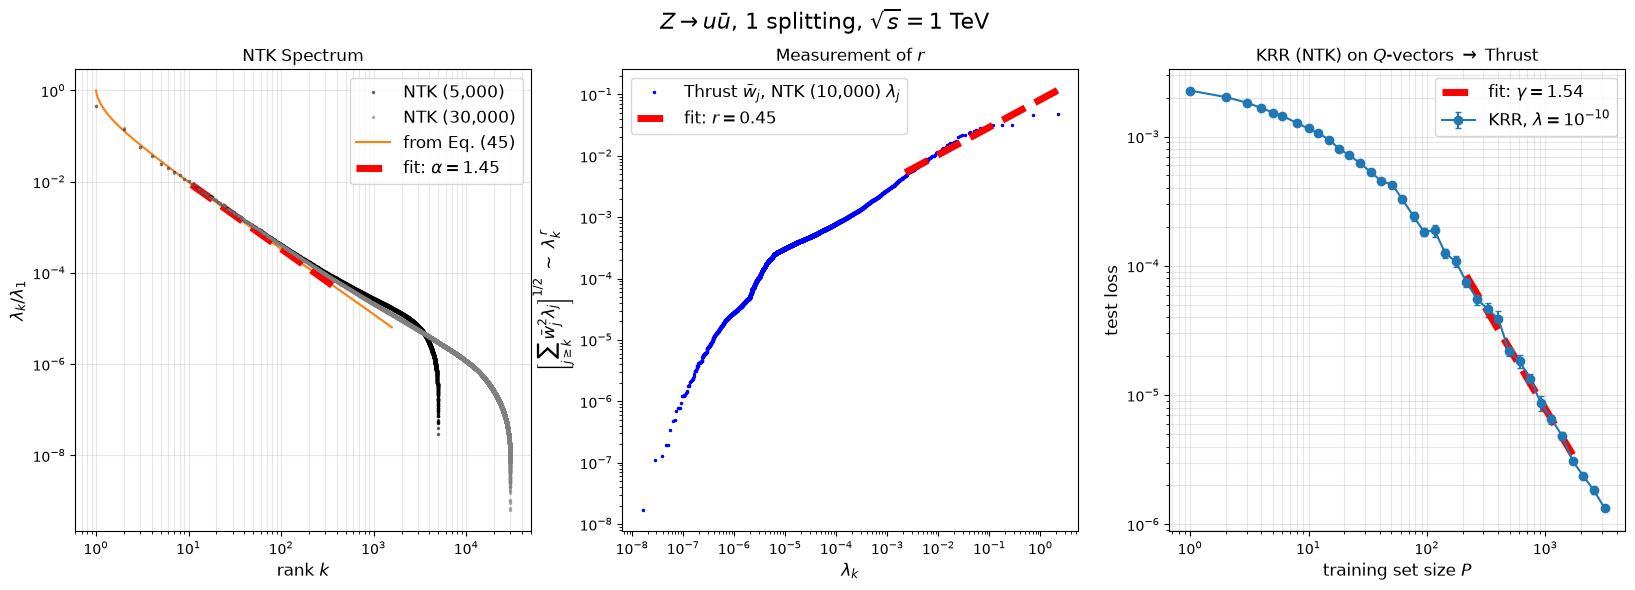

In [38]:
plot_scaling('Z1', (10, 500), (1, 100), (200, 2000))
plot_scaling('Z1_1TeV', (10, 500), (1, 100), (200, 2000))